# Chapitre 3 - Exercices 3.7 à 3.10

Ce notebook traite les quatre derniers exercices du chapitre 3 :

- **3.7** : LSM ou B-tree ? Dimensionner disque et SSD pour une charge donnée
  (calcul) ;
- **3.8** : choisir ses index secondaires et couvrants, mesures à l'appui avec SQLite
  (mini-lab) ;
- **3.9** : intersection de postings lists et recherche floue (calcul et mini-lab) ;
- **3.10** : stockage en colonnes, compression et cube de données (calcul et
  mini-lab).

In [1]:
import math
import random
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)


def meilleur_temps(f, rep=5):
    best = float("inf")
    for _ in range(rep):
        t0 = time.perf_counter()
        f()
        best = min(best, time.perf_counter() - t0)
    return best

## Exercice 3.7 : LSM ou B-tree ? Dimensionner disque et SSD

**Énoncé.** Un service de télémétrie reçoit 50 000 écritures par seconde
d'enregistrements de 200 octets (clés aléatoires) et sert 20 000 lectures ponctuelles
par seconde. Il dispose d'un SSD de 4 To : 1 Go/s de bande passante d'écriture,
400 000 IOPS de lecture aléatoire, et une endurance de 1 DWPD (on peut écrire 4 To par
jour pendant 5 ans). On compare :

- un **B-tree** (pages de 8 Kio, cache de pages : on estime qu'en moyenne chaque
  écriture fait réécrire un quart de page au point de reprise, plus le WAL) ;
- un **LSM** en leveled, d'amplification d'écriture 12 (WAL compris), avec une lecture
  de bloc par lecture ponctuelle en moyenne (filtres de Bloom) plus 10 % de faux
  positifs et de niveaux non filtrés.

1. Calculer l'amplification d'écriture du B-tree et le débit disque d'écriture des deux
   moteurs. Tiennent-ils sur le SSD ?
2. Calculer la durée de vie du SSD dans chaque cas.
3. Calculer les IOPS de lecture (pages internes du B-tree en cache). Conclure.

**Rappels.** Amplification d'écriture, usure des SSD, lectures prévisibles du B-tree
contre lectures dépendant de la compaction (section *Comparing B-Trees and LSM-Trees* ;
cours 3, section 5).

**Solution.**

*1.* B-tree : par écriture de 200 octets, un quart de page de 8 Kio (2 048 octets) au
point de reprise plus 200 octets de WAL, soit
$\mathrm{WA} = (2\,048 + 200)/200 \approx 11{,}2$. Débit utile :
$5 \times 10^4 \times 200 = 10$ Mo/s. Débit disque : 112 Mo/s pour le B-tree, 120 Mo/s
pour le LSM. Les deux tiennent largement dans 1 Go/s : à ce niveau de charge, c'est
l'**écriture aléatoire** de pages par le B-tree (environ 12 500 pages de 8 Kio par
seconde, soit $5 \times 10^4 / 4$) qui pourrait gêner un disque magnétique, pas un SSD.

*2.* Volume écrit par jour : $112\,\text{Mo/s} \times 86\,400 \approx 9{,}7$ To pour le
B-tree, $10{,}4$ To pour le LSM. L'endurance est de 4 To par jour pendant 5 ans, soit
$7\,300$ To au total : environ $7\,300 / 9{,}7 \approx 750$ jours (2 ans) pour le
B-tree, 700 jours pour le LSM. Les deux **usent le SSD deux fois trop vite**. Leviers :
compresser (le LSM compresse ses blocs bien mieux), réduire l'amplification (size-tiered
pour le LSM, plus grand intervalle de reprise pour le B-tree), ou provisionner plus de
disques. Avec ces hypothèses les deux moteurs sont proches : le livre a raison de dire
qu'il faut mesurer **sa** charge.

*3.* B-tree : une E/S par lecture (la feuille), 20 000 IOPS. LSM : $1{,}1 \times 20\,000
= 22\,000$ IOPS. Les deux restent très loin des 400 000 IOPS du SSD. Mais la compaction
du LSM lit aussi : elle relit environ autant qu'elle écrit, en séquentiel.

In [2]:
utile = 5e4 * 200
wa_bt = (8192 / 4 + 200) / 200
moteurs = pd.DataFrame({"B-tree": [wa_bt, 1.0], "LSM leveled": [12.0, 1.1]},
                       index=["amplification d'écriture", "E/S par lecture"]).T
moteurs["écriture disque (Mo/s)"] = utile * moteurs["amplification d'écriture"] / 1e6
moteurs["To écrits par jour"] = moteurs["écriture disque (Mo/s)"] * 86_400 / 1e6
moteurs["durée de vie du SSD (années)"] = 4 * 365 * 5 / moteurs["To écrits par jour"] / 365
moteurs["IOPS de lecture"] = 2e4 * moteurs["E/S par lecture"]
moteurs["part de la bande passante (%)"] = moteurs["écriture disque (Mo/s)"] / 1000 * 100
moteurs

,amplification d'écriture,E/S par lecture,écriture disque (Mo/s),To écrits par jour,durée de vie du SSD (années),IOPS de lecture,part de la bande passante (%)
B-tree,11.24,1.0,112.4,9.711,2.059,20000.0,11.24
LSM leveled,12.00,1.1,120.0,10.368,1.929,22000.0,12.00


**Vérification graphique** : durée de vie du SSD en fonction de l'amplification
d'écriture, et effet d'une compression des blocs (taux 3) pour le LSM.

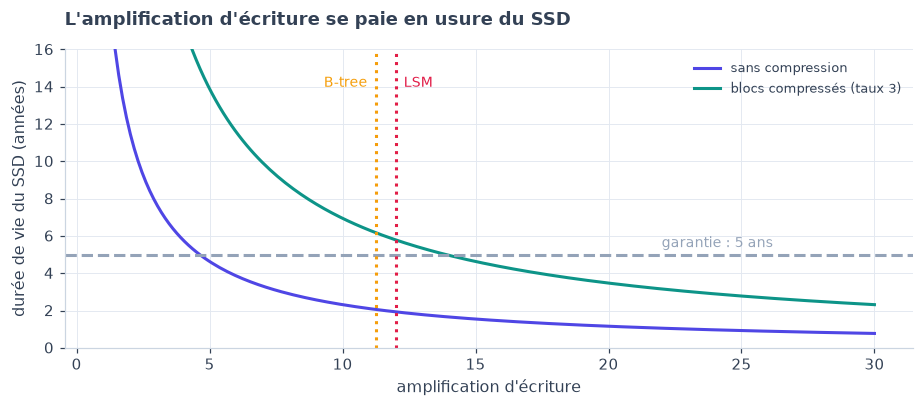

In [3]:
wa = np.linspace(1, 30, 200)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(wa, 7300 / (utile * wa * 86_400 / 1e12) / 365, color=INDIGO, label="sans compression")
ax.plot(wa, 7300 / (utile * wa / 3 * 86_400 / 1e12) / 365, color=TEAL, label="blocs compressés (taux 3)")
ax.axhline(5, color=GRAY, ls="--"); ax.text(22, 5.4, "garantie : 5 ans", color=GRAY, fontsize=9)
for nom, w in [("B-tree", wa_bt), ("LSM", 12)]:
    ax.axvline(w, color=ROSE if nom == "LSM" else AMBER, ls=":")
    if nom == "LSM":
        ax.text(w + 0.3, 14, nom, color=ROSE, fontsize=9)
    else:
        ax.text(w - 0.3, 14, nom, color=AMBER, fontsize=9, ha="right")
ax.set_ylim(0, 16)
ax.set_xlabel("amplification d'écriture"); ax.set_ylabel("durée de vie du SSD (années)")
ax.set_title("L'amplification d'écriture se paie en usure du SSD")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

> **À retenir.** Pour dimensionner, on multiplie le débit utile par l'amplification
> d'écriture : on obtient la bande passante consommée et l'usure du SSD. Compression et
> choix de la compaction pèsent autant que la famille de moteur.

## Exercice 3.8 : Choisir ses index secondaires et couvrants (mini-lab SQLite)

**Énoncé.** Une table `commandes(id, client, statut, date, montant, adresse)` de
200 000 lignes reçoit trois requêtes fréquentes :

- **Q1** : les commandes d'un client (`WHERE client = ?`) ;
- **Q2** : le montant total d'un client sur un mois (`SUM(montant) WHERE client = ? AND
  date BETWEEN ? AND ?`) ;
- **Q3** : le nombre de commandes par statut (`WHERE statut = ?`, 5 statuts, dont un
  représente 60 % des lignes).

1. Proposer des index ; prévoir lesquels seront utilisés et pourquoi un index sur
   `statut` est peu utile pour le statut majoritaire.
2. Mesurer avec SQLite le plan et le temps de chaque requête, et le coût des index à
   l'insertion.
3. Conclure sur le compromis lecture / écriture.

**Rappels.** Index secondaires, index concaténé (préfixe), index couvrant, sélectivité
(sections *Other Indexing Structures* et
*Storing values within the index* ; cours 4,
sections 1 à 3).

**Solution (prévisions).** Un index concaténé `(client, date)` sert Q1 (préfixe
`client`) et Q2 (préfixe complet, intervalle sur `date`) ; en y incluant `montant`
(`(client, date, montant)`), il **couvre** Q2. Pour Q3, un index sur `statut` aide les
statuts rares ; pour le statut majoritaire (60 % des lignes), parcourir l'index puis la
table coûterait plus qu'un parcours complet. Mais pour un simple `COUNT(*)`, l'index sur
`statut` couvre la requête : SQLite peut compter dans l'index, plus petit que la table.

In [4]:
rng = np.random.default_rng(0)
N = 200_000
rows = list(zip(range(N), S.zipf_keys(N, 20_000, s=0.7, seed=1).tolist(),
                rng.choice(["livrée", "expédiée", "payée", "annulée", "litige"], N, p=[0.6, 0.2, 0.15, 0.04, 0.01]),
                rng.integers(0, 365, N).tolist(), np.round(rng.lognormal(3, 0.7, N), 2).tolist(), ["x" * 120] * N))
REQ = {"Q1": "SELECT id, montant FROM commandes WHERE client = 77",
       "Q2": "SELECT SUM(montant) FROM commandes WHERE client = 77 AND date BETWEEN 100 AND 130",
       "Q3 (litige)": "SELECT COUNT(*) FROM commandes WHERE statut = 'litige'",
       "Q3 (livrée)": "SELECT COUNT(*) FROM commandes WHERE statut = 'livrée'"}
CONFIGS = {"aucun index": [],
           "(client)": ["CREATE INDEX i1 ON commandes(client)"],
           "(client, date)": ["CREATE INDEX i2 ON commandes(client, date)"],
           "(client, date, montant) + (statut)": ["CREATE INDEX i3 ON commandes(client, date, montant)",
                                                   "CREATE INDEX i4 ON commandes(statut)"]}
resultats, plans, insertion = [], {}, {}
for nom, ddl in CONFIGS.items():
    con = sqlite3.connect(":memory:")
    con.execute("CREATE TABLE commandes (id INTEGER PRIMARY KEY, client INT, statut TEXT, date INT, "
                "montant REAL, adresse TEXT)")
    for d in ddl:
        con.execute(d)
    t0 = time.perf_counter()
    con.executemany("INSERT INTO commandes VALUES (?, ?, ?, ?, ?, ?)", rows)
    con.commit()
    insertion[nom] = (time.perf_counter() - t0) / N * 1e6
    for q, sql in REQ.items():
        plan = " | ".join(r[-1] for r in con.execute("EXPLAIN QUERY PLAN " + sql))
        resultats.append(dict(configuration=nom, requete=q,
                              us=meilleur_temps(lambda: con.execute(sql).fetchall(), 5) * 1e6, plan=plan))
    con.close()
res = pd.DataFrame(resultats)
res.pivot(index="requete", columns="configuration", values="us")[list(CONFIGS)].round(0)

configuration,aucun index,(client),"(client, date)","(client, date, montant) + (statut)"
requete,,,,
Q1,4264.0,2.0,2.0,2.0
Q2,3873.0,1.0,1.0,1.0
Q3 (litige),5230.0,5564.0,5333.0,30.0
Q3 (livrée),5746.0,5981.0,5574.0,1783.0


In [5]:
res[res.configuration == "(client, date, montant) + (statut)"][["requete", "plan"]]

,requete,plan
12,Q1,SEARCH commandes USING COVERING INDEX i3 (clie...
13,Q2,SEARCH commandes USING COVERING INDEX i3 (clie...
14,Q3 (litige),SEARCH commandes USING COVERING INDEX i4 (stat...
15,Q3 (livrée),SEARCH commandes USING COVERING INDEX i4 (stat...


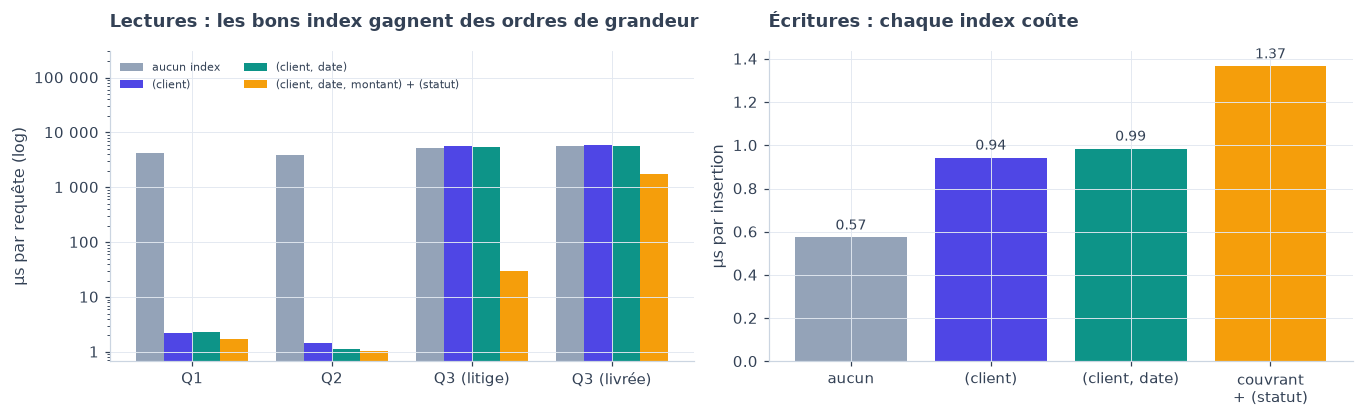

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
piv = res.pivot(index="requete", columns="configuration", values="us")[list(CONFIGS)]
x = np.arange(len(piv))
for j, (nom, c) in enumerate(zip(CONFIGS, [GRAY, INDIGO, TEAL, AMBER])):
    axes[0].bar(x + (j - 1.5) * 0.2, piv[nom], 0.2, color=c, label=nom)
axes[0].set_yscale("log"); S.plain_log_ticks(axes[0])
axes[0].set_xticks(x, piv.index); axes[0].set_ylabel("µs par requête (log)")
axes[0].set_title("Lectures : les bons index gagnent des ordres de grandeur")
axes[0].set_ylim(top=3e5)
axes[0].legend(fontsize=7.5, ncol=2, loc="upper left")
ins = pd.Series(insertion)
axes[1].bar(range(len(ins)), ins.values, color=[GRAY, INDIGO, TEAL, AMBER])
axes[1].set_xticks(range(len(ins)), ["aucun", "(client)", "(client, date)", "couvrant\n+ (statut)"])
annotate_bars(axes[1], "{:.2f}")
axes[1].set_ylabel("µs par insertion"); axes[1].set_title("Écritures : chaque index coûte")
finish(fig)
plt.show()

**Lecture des résultats.** Q1 et Q2 passent d'un parcours complet (`SCAN`) à une
recherche dans l'index (`SEARCH ... USING INDEX`), et Q2 devient `USING COVERING INDEX`
avec l'index `(client, date, montant)` : la table n'est plus lue. Pour Q3, l'index sur
`statut` couvre le `COUNT(*)` : le statut rare est quasi instantané, le statut
majoritaire reste coûteux (il faut compter 120 000 entrées), mais moins qu'un parcours de
la table. Côté écriture, chaque index ajouté alourdit l'insertion : c'est le compromis
du livre, qu'on arbitre d'après la fréquence des requêtes.

> **À retenir.** Un index concaténé sert tous les préfixes de ses colonnes ; y ajouter
> les colonnes lues le rend couvrant. Un index sur une colonne peu sélective aide peu,
> sauf s'il couvre la requête. Et chaque index se paie à l'écriture.